# Fine-tuning Run 1: Detector and Hard Negatives

This run continues from the initial YOLO26-m detector using the prepared replay and hard-negative dataset. It evaluates detector checkpoints without the crop verifier or temporal alarm logic.


## 01. Run settings and inputs

Defines the initial detector checkpoint, the prepared dataset archive, the output paths, and the training budget.


In [1]:
# Step 1 — paths and settings (does not start training)
import os, sys, json, time, shutil, tarfile, csv, math, subprocess
from pathlib import Path

VOL = Path(os.environ.get("FIRE_VOLUME", "/root/lab/volume"))
WORK = Path("/root/work")
ARCHIVE = VOL / "cache" / "finetune_v4.tar"
DATA_DIR = WORK / "finetune_v4"
BASE_WEIGHTS = VOL / "fire_project" / "weights" / "detector.pt"
RUNS = VOL / "runs"
RUN_NAME = "det_v3_hardneg_v4"
RUN_DIR = RUNS / RUN_NAME
NEW_WEIGHTS = VOL / "fire_project" / "weights" / "detector_v3_hardneg.pt"
REPORTS = VOL / "fire_project" / "reports" / "hardneg_v4"

# Starting values for your approx. $15 GPU budget; tune only after seeing actual performance.
TRAIN_HOURS = 1.50                  # training time limit (hours), NOT total session life
IMGSZ = 800                         # same as your previous YOLO26-m run
BATCH = 32                          # start conservatively; lower to 16 if CUDA OOM
WORKERS = 6                         # for the 8-CPU Modal configuration
DEVICE = 0
LEARNING_RATE = 0.0003
MAX_EPOCHS = 120                     # time=TRAIN_HOURS is the effective stopping limit
RESUME_INTERRUPTED = False         # set True only if a prior v3 run was interrupted
RUN_BASELINE_HARDVAL = True        # compare OLD detector on new hard-validation set
RUN_AFTER_TRAIN_EVAL = True         # compare NEW detector on hard-validation set
RUN_ORIGINAL_VAL_EVAL = False      # optional extra full validation on 3,829 images
RUN_NEGATIVE_FP_CHECK = True        # lightweight detector-only false positive check
NEGATIVE_SAMPLE = 200              # hard_val negatives, shared sample for both models

assert VOL.is_dir(), f"Modal Volume not mounted at {VOL}"
assert ARCHIVE.is_file(), f"Missing prepared archive: {ARCHIVE}"
assert BASE_WEIGHTS.is_file(), f"Missing previous trained weights: {BASE_WEIGHTS}"
assert ARCHIVE.stat().st_size > 100_000_000, "Prepared archive is unexpectedly small"
assert BASE_WEIGHTS.resolve() != NEW_WEIGHTS.resolve()
for p in (WORK, RUNS, REPORTS, NEW_WEIGHTS.parent): p.mkdir(parents=True, exist_ok=True)
print("Persistent Volume:", VOL)
print("Prepared dataset:", ARCHIVE, f"({ARCHIVE.stat().st_size / 1e9:.2f} GB)")
print("Existing weights:", BASE_WEIGHTS)
print("Candidate new weights:", NEW_WEIGHTS)
print("Checkpoint folder:", RUN_DIR)
print("No training started yet.")

Persistent Volume: /root/lab/volume
Prepared dataset: /root/lab/volume/cache/finetune_v4.tar (1.23 GB)
Existing weights: /root/lab/volume/fire_project/weights/detector.pt
Candidate new weights: /root/lab/volume/fire_project/weights/detector_v3_hardneg.pt
Checkpoint folder: /root/lab/volume/runs/det_v3_hardneg_v4
No training started yet.


## 02. Training environment

Checks the required packages and confirms that CUDA is available.


In [3]:
# Fix libxcb / OpenCV system libs, then install Ultralytics and check GPU
import subprocess, sys
subprocess.run("apt-get update -qq && apt-get install -y -qq libxcb1 libgl1 libglib2.0-0 libsm6 libxext6 libxrender1 ca-certificates",
               shell=True, check=False)

from importlib.metadata import version, PackageNotFoundError
try:
    uv = version("ultralytics")
except PackageNotFoundError:
    uv = None
if uv != "8.4.194":
    print(f"Installing Ultralytics 8.4.194 (found: {uv}).")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.194", "PyYAML>=6,<7"])
else:
    print("Ultralytics version already matches:", uv)

import torch, yaml, ultralytics
from ultralytics import YOLO
print("Ultralytics:", ultralytics.__version__, "Torch:", torch.__version__)
assert torch.cuda.is_available(), "CUDA GPU not detected! DO NOT train on CPU."
print("GPU:", torch.cuda.get_device_name(0))
print("GPU VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / (1024**3), 1))

debconf: delaying package configuration, since apt-utils is not installed


Selecting previously unselected package openssl.
(Reading database ... 4393 files and directories currently installed.)
Preparing to unpack .../00-openssl_3.0.2-0ubuntu1.30_amd64.deb ...
Unpacking openssl (3.0.2-0ubuntu1.30) ...
Selecting previously unselected package ca-certificates.
Preparing to unpack .../01-ca-certificates_20260816ubuntu0.22.04.2_all.deb ...
Unpacking ca-certificates (20260816ubuntu0.22.04.2) ...
Selecting previously unselected package libmd0:amd64.
Preparing to unpack .../02-libmd0_1.0.4-1build1_amd64.deb ...
Unpacking libmd0:amd64 (1.0.4-1build1) ...
Selecting previously unselected package libbsd0:amd64.
Preparing to unpack .../03-libbsd0_0.11.5-1_amd64.deb ...
Unpacking libbsd0:amd64 (0.11.5-1) ...
Selecting previously unselected package libelf1:amd64.
Preparing to unpack .../04-libelf1_0.186-1ubuntu0.1_amd64.deb ...
Unpacking libelf1:amd64 (0.186-1ubuntu0.1) ...
Selecting previously unselected package libexpat1:amd64.
Preparing to unpack .../05-libexpat1_2.4.7-

## 03. Prepare the archive for training

Extracts or reuses the dataset, rewrites its local YAML paths, and checks the prepared splits.


In [4]:
# Safe extraction; do not unpack each time if the local data is already complete.
def extract_safe(tar_path, destination):
    destination = destination.resolve()
    destination.mkdir(parents=True, exist_ok=True)
    with tarfile.open(tar_path, "r:*") as tf:
        for member in tf.getmembers():
            target = (destination / member.name).resolve()
            if not target.is_relative_to(destination):
                raise ValueError(f"Unsafe archive path: {member.name}")
            if member.issym() or member.islnk() or not (member.isfile() or member.isdir()):
                raise ValueError(f"Unexpected archive member: {member.name}")
        if sys.version_info >= (3, 12):
            tf.extractall(destination, filter="data")
        else:
            tf.extractall(destination)

if not ((DATA_DIR / "images" / "train").is_dir() and (DATA_DIR / "audit.json").is_file()):
    print("Extracting about 1.23 GB of prepared data to fast local storage...")
    extract_safe(ARCHIVE, WORK)
else:
    print("Reusing extracted local dataset.")

assert DATA_DIR.is_dir(), f"Expected archive to create: {DATA_DIR}"
for split in ("train", "val", "test", "hard_val", "hard_test"):
    assert (DATA_DIR / "images" / split).is_dir(), f"Missing images/{split}"
    assert (DATA_DIR / "labels" / split).is_dir(), f"Missing labels/{split}"

for fname in ("data.yaml", "hard_val.yaml"):
    p = DATA_DIR / fname
    cfg = yaml.safe_load(p.read_text())
    cfg["path"] = str(DATA_DIR.resolve())  # IMPORTANT: old CPU path is not valid here
    assert cfg.get("names") in ({0: "fire", 1: "smoke"}, ["fire", "smoke"]), cfg.get("names")
    p.write_text(yaml.safe_dump(cfg, sort_keys=False))
    print(fname, "=>", p, "root:", cfg["path"])

DATA_YAML = DATA_DIR / "data.yaml"
HARD_YAML = DATA_DIR / "hard_val.yaml"
AUDIT = json.loads((DATA_DIR / "audit.json").read_text())
print("Dataset source audit:")
print(json.dumps({k: AUDIT.get(k) for k in ("old_replay", "new_train_by_source", "new_negatives_by_source", "splits")}, indent=2))
for split, expected in (("train", 12258), ("val", 3829), ("test", 1958), ("hard_val", 869), ("hard_test", 491)):
    count = len(list((DATA_DIR / "images" / split).glob("*.jpg")))
    print(f"{split:10s} {count:6,d} images")
    if count != expected:
        print(f"WARNING: expected {expected} from your earlier screenshot; investigate before training.")
assert len(list((DATA_DIR / "images" / "train").glob("*.jpg"))) > 10000, "Unexpectedly small dataset."
assert (AUDIT.get("new_train_by_source") or {}), "No new hard-negative data in audit."
assert sum((AUDIT.get("new_negatives_by_source") or {}).values()) >= 1000, "Not enough new negatives."
assert (DATA_DIR / "images" / "hard_val").is_dir()
print("Dataset is present and ready. NO training started.")

Extracting about 1.23 GB of prepared data to fast local storage...
data.yaml => /root/work/finetune_v4/data.yaml root: /root/work/finetune_v4
hard_val.yaml => /root/work/finetune_v4/hard_val.yaml root: /root/work/finetune_v4
Dataset source audit:
{
  "old_replay": 10000,
  "new_train_by_source": {
    "fireandsmoke_part1": 981,
    "fireandsmoke_part2": 1277
  },
  "new_negatives_by_source": {
    "fireandsmoke_part1": 579,
    "fireandsmoke_part2": 875
  },
  "splits": {
    "train": {
      "total": 12258,
      "positive": 9304,
      "negative": 2954
    },
    "val": {
      "total": 3829,
      "positive": 2214,
      "negative": 1615
    },
    "test": {
      "total": 1958,
      "positive": 1151,
      "negative": 807
    },
    "hard_val": {
      "total": 869,
      "positive": 282,
      "negative": 587
    },
    "hard_test": {
      "total": 491,
      "positive": 282,
      "negative": 209
    }
  }
}
train      12,258 images
val         3,829 images
test        1,958 im

## 04. Validate the starting checkpoint

Loads the initial detector and verifies the fire and smoke class order.


In [5]:
original = YOLO(str(BASE_WEIGHTS))
classes = original.names
print("Checkpoint architecture:", original.model.__class__.__name__)
print("Checkpoint classes:", classes)
assert len(classes) == 2 and str(classes[0]).lower() == "fire" and str(classes[1]).lower() == "smoke", \
    "Class mapping is wrong. STOP rather than corrupting labels."
del original
if torch.cuda.is_available(): torch.cuda.empty_cache()
print("Old weights are valid. Ready for fine-tuning.")

Checkpoint architecture: DetectionModel
Checkpoint classes: {0: 'fire', 1: 'smoke'}
Old weights are valid. Ready for fine-tuning.


## 05. Measure the detector baseline

Evaluates the initial detector on hard validation and saves its baseline metrics.


In [6]:
BASELINE_PATH = REPORTS / "baseline_hard_val.json"

def metrics_dict(m):
    return {
        "mAP50": float(m.box.map50),
        "mAP50_95": float(m.box.map),
        "precision": float(m.box.mp),
        "recall": float(m.box.mr),
        "per_class_mAP50": {str(m.names.get(i, i)): float(ap) for i, ap in enumerate(m.box.ap50)},
    }

def run_yolo_validation(weights, dataset_yaml, tag):
    print(f"Validating {tag}, using {dataset_yaml.name}")
    v = YOLO(str(weights)).val(
        data=str(dataset_yaml), split="val", imgsz=IMGSZ,
        batch=16, workers=WORKERS, device=DEVICE, plots=False,
        verbose=False, project=str(REPORTS), name=f"validate_{tag}", exist_ok=True
    )
    return metrics_dict(v)

if RUN_BASELINE_HARDVAL:
    if BASELINE_PATH.is_file():
        baseline_metrics = json.loads(BASELINE_PATH.read_text())
        print("Reusing existing baseline metrics.")
    else:
        baseline_metrics = run_yolo_validation(BASE_WEIGHTS, HARD_YAML, "baseline_hard_val")
        BASELINE_PATH.write_text(json.dumps(baseline_metrics, indent=2))
    print("BASELINE hard_val metrics:", json.dumps(baseline_metrics, indent=2))
else:
    print("Baseline metric evaluation skipped.")

Validating baseline_hard_val, using hard_val.yaml
Ultralytics 8.4.194 🚀 Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA A100-SXM4-80GB, 81175MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1282.0±718.0 MB/s, size: 74.6 KB)
val: Scanning /root/work/finetune_v4/labels/hard_val... 869 images, 587 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 869/869 2.2Kit/s 0.4s0.1ss
val: New cache created: /root/work/finetune_v4/labels/hard_val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 55/55 11.6it/s 4.7s0.2s
                   all        869        539      0.596      0.658      0.616        0.3
Speed: 0.3ms preprocess, 3.7ms inference, 0.0ms loss, 0.3ms postprocess per image
BASELINE hard_val metrics: {
  "mAP50": 0.6161921080426997,
  "mAP50_95": 0.30011190547807814,
  "precision": 0.5956376403364242,
  "recall": 0.6580640390979169,
  "per_cla

## 06. Fine-tune YOLO26-m

Starts from the initial detector and uses the original validation split to select the candidate checkpoint.


In [8]:
# Training cell: runs in a clean subprocess (avoids the stale worker error)
import json, sys, subprocess, textwrap, datetime
TRAIN_MARKER = RUN_DIR / "finetuning_finished.json"
LAST = RUN_DIR / "weights" / "last.pt"
BEST = RUN_DIR / "weights" / "best.pt"

cfg = dict(base=str(BASE_WEIGHTS), data=str(DATA_YAML), imgsz=IMGSZ, batch=BATCH,
           workers=WORKERS, device=DEVICE, epochs=MAX_EPOCHS, hours=TRAIN_HOURS,
           project=str(RUNS), name=RUN_NAME, lr=LEARNING_RATE, last=str(LAST))
script = textwrap.dedent('''
    import json, sys
    from ultralytics import YOLO
    c = json.loads(sys.argv[1]); resume = sys.argv[2] == "1"
    if resume:
        YOLO(c["last"]).train(resume=True, data=c["data"], device=c["device"],
                              workers=c["workers"], batch=c["batch"], time=c["hours"])
    else:
        m = YOLO(c["base"])
        m.train(data=c["data"], imgsz=c["imgsz"], batch=c["batch"], workers=c["workers"],
                device=c["device"], epochs=c["epochs"], time=c["hours"],
                project=c["project"], name=c["name"], exist_ok=True,
                optimizer="AdamW", lr0=c["lr"], lrf=0.1, warmup_epochs=1.0, cos_lr=True,
                patience=15, hsv_h=0.005, hsv_s=0.50, hsv_v=0.30, degrees=0.0,
                translate=0.08, scale=0.35, fliplr=0.5, mosaic=0.4, mixup=0.0,
                close_mosaic=3, amp=True, cache=False, plots=True, save=True,
                save_period=3, val=True, seed=20261111, deterministic=False)
''')
(WORK / "train_v4.py").write_text(script)

def run_training(resume):
    p = subprocess.Popen([sys.executable, "-u", str(WORK / "train_v4.py"), json.dumps(cfg), "1" if resume else "0"],
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        line = line.rstrip()
        if line: print(line)
    p.wait()
    print("Training process exit code:", p.returncode)

if TRAIN_MARKER.exists() and BEST.is_file():
    print("Training already finished. Best checkpoint:", BEST)
elif LAST.exists():
    if not RESUME_INTERRUPTED:
        raise RuntimeError("A previous run exists. Set RESUME_INTERRUPTED=True in Step 1 to resume it.")
    run_training(resume=True)
else:
    run_training(resume=False)

if BEST.is_file():
    TRAIN_MARKER.write_text(json.dumps({
        "saved_at_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
        "starting_weights": str(BASE_WEIGHTS), "new_data": str(ARCHIVE),
        "best_checkpoint": str(BEST), "train_hours_limit": TRAIN_HOURS}, indent=2))
    print("Training checkpoint saved:", BEST)
else:
    print("No best.pt yet. Check the log above.")

New https://pypi.org/project/ultralytics/8.4.212 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.194 🚀 Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA A100-SXM4-80GB, 81175MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=3, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/root/work/finetune_v4/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=120, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.005, hsv_s=0.5, hsv_v=0.3, imgsz=800, iou=0.7, kobj=1.0, line_width=None, lr0=0.0003, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/roo

## 07. Export and evaluate the candidate

Saves the selected checkpoint separately and scores it on the original and hard validation splits.


In [9]:
assert BEST.is_file(), f"No trained checkpoint. Finish Step 6 first: {BEST}"
assert NEW_WEIGHTS != BASE_WEIGHTS
if not NEW_WEIGHTS.is_file() or NEW_WEIGHTS.stat().st_size != BEST.stat().st_size:
    shutil.copy2(BEST, NEW_WEIGHTS)
print("Candidate weights saved:", NEW_WEIGHTS, f"({NEW_WEIGHTS.stat().st_size / 1e6:.1f} MB)")
print("Original detector remains:", BASE_WEIGHTS)
print("Original verifier remains:", VOL / "fire_project" / "weights" / "verifier.pt")

FINETUNED_PATH = REPORTS / "candidate_hard_val.json"
if RUN_AFTER_TRAIN_EVAL:
    if FINETUNED_PATH.is_file():
        new_metrics = json.loads(FINETUNED_PATH.read_text())
    else:
        new_metrics = run_yolo_validation(NEW_WEIGHTS, HARD_YAML, "candidate_hard_val")
        FINETUNED_PATH.write_text(json.dumps(new_metrics, indent=2))
    print("\nHARD-VALIDATION METRICS:")
    if BASELINE_PATH.exists():
        old_metrics = json.loads(BASELINE_PATH.read_text())
        for k in ("precision", "recall", "mAP50", "mAP50_95"):
            print(f"{k:12s}  original={old_metrics.get(k, 0):.4f}  fine-tuned={new_metrics.get(k,0):.4f}  "
                  f"delta={new_metrics.get(k,0)-old_metrics.get(k,0):+.4f}")
    else:
        print(json.dumps(new_metrics, indent=2))
else:
    print("Hard-validation evaluation skipped.")

if RUN_ORIGINAL_VAL_EVAL:
    orig_val = run_yolo_validation(NEW_WEIGHTS, DATA_YAML, "candidate_original_val")
    (REPORTS / "candidate_original_val.json").write_text(json.dumps(orig_val, indent=2))
    print("Candidate performance on original val:", orig_val)

Candidate weights saved: /root/lab/volume/fire_project/weights/detector_v3_hardneg.pt (44.0 MB)
Original detector remains: /root/lab/volume/fire_project/weights/detector.pt
Original verifier remains: /root/lab/volume/fire_project/weights/verifier.pt
Validating candidate_hard_val, using hard_val.yaml
Ultralytics 8.4.194 🚀 Python-3.11.5 torch-2.15.0+cu132 CUDA:0 (NVIDIA A100-SXM4-80GB, 81175MiB)
YOLO26m summary (fused): 130 layers, 20,350,994 parameters, 0 gradients, 68.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1467.2±725.3 MB/s, size: 74.1 KB)
val: Scanning /root/work/finetune_v4/labels/hard_val.cache... 869 images, 587 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 869/869 158.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 55/55 11.4it/s 4.8s0.2s
                   all        869        539      0.658      0.669      0.674       0.35
Speed: 0.3ms preprocess, 3.6ms inference, 0.0ms loss, 0.4ms postproce

## 08. Compare negative-image detections

Counts detector false positives on the same hard-validation negatives at confidence 0.20. These are image-level detections, not video alarms.


In [10]:
import random
FP_REPORT = REPORTS / "negative_fp_comparison.json"

if RUN_NEGATIVE_FP_CHECK:
    random.seed(20261111)
    hard_imgs = sorted((DATA_DIR / "images" / "hard_val").glob("*.jpg"))
    negatives = [im for im in hard_imgs if not (DATA_DIR / "labels" / "hard_val" / (im.stem + ".txt")).read_text().strip()]
    sample = random.sample(negatives, min(NEGATIVE_SAMPLE, len(negatives)))
    print(f"Testing {len(sample)} hard_val negatives at detector conf=0.20")
    assert sample, "No empty-labeled hard-val images"

    def fp_summary(weights, images):
        detector = YOLO(str(weights))
        fp_images = 0
        false_boxes = 0
        for j in range(0, len(images), 16):
            batch_paths = [str(p) for p in images[j:j+16]]
            result = detector.predict(
                batch_paths, imgsz=IMGSZ, conf=0.20, iou=0.5,
                max_det=50, batch=16, device=DEVICE, verbose=False
            )
            for r in result:
                n = len(r.boxes) if r.boxes is not None else 0
                fp_images += int(n > 0)
                false_boxes += n
        return {"total_negative_images": len(images), "false_positive_images": fp_images,
                "fp_image_fraction": fp_images/len(images), "false_detection_boxes": false_boxes}

    if FP_REPORT.is_file():
        comparison = json.loads(FP_REPORT.read_text())
    else:
        comparison = {
            "original": fp_summary(BASE_WEIGHTS, sample),
            "fine_tuned": fp_summary(NEW_WEIGHTS, sample),
            "threshold": 0.20, "split": "hard_val",
            "note": "detector image-level FP only, not final video alarm FP rate"
        }
        FP_REPORT.write_text(json.dumps(comparison, indent=2))
    print(json.dumps(comparison, indent=2))
else:
    print("Detector-only negative comparison skipped.")

Testing 200 hard_val negatives at detector conf=0.20
{
  "original": {
    "total_negative_images": 200,
    "false_positive_images": 27,
    "fp_image_fraction": 0.135,
    "false_detection_boxes": 41
  },
  "fine_tuned": {
    "total_negative_images": 200,
    "false_positive_images": 25,
    "fp_image_fraction": 0.125,
    "false_detection_boxes": 31
  },
  "threshold": 0.2,
  "split": "hard_val",
  "note": "detector image-level FP only, not final video alarm FP rate"
}


## 09. Inspect the training curves

Plots recorded metrics from the training CSV without starting another training run.


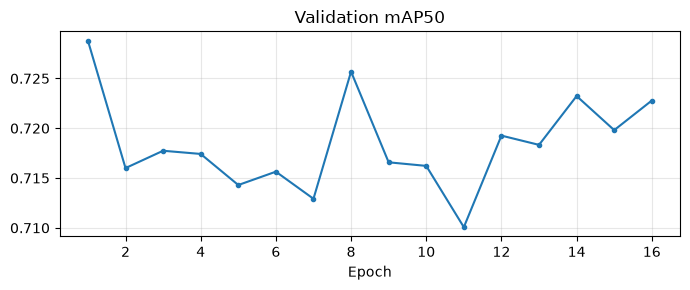

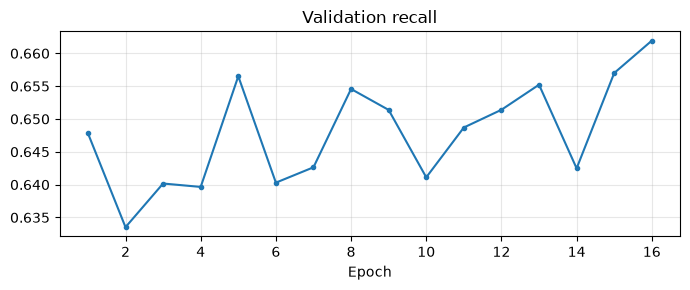

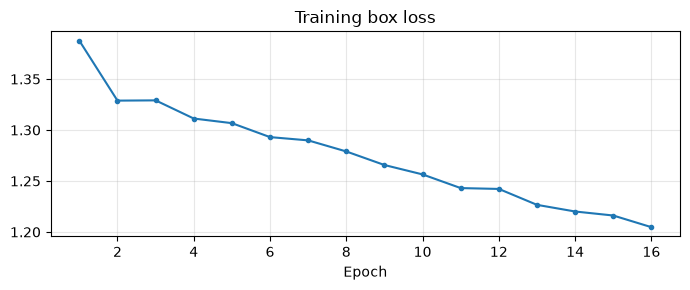

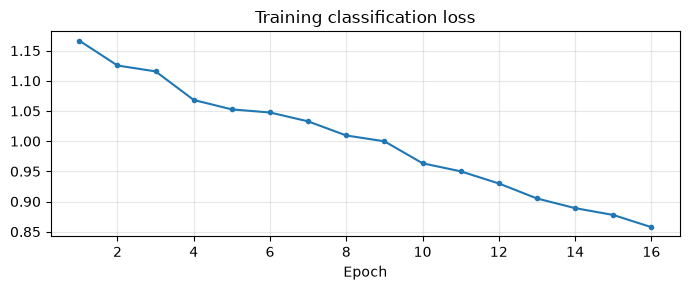

In [13]:
results_csv = RUN_DIR / "results.csv"
if results_csv.is_file():
    import matplotlib.pyplot as plt
    with results_csv.open(newline="") as f:
        rows = list(csv.DictReader(f))
    def col(k):
        return [float(r.get(k, "nan")) if r.get(k) else math.nan for r in rows]
    for k, label in [
        ("metrics/mAP50(B)", "Validation mAP50"),
        ("metrics/recall(B)", "Validation recall"),
        ("train/box_loss", "Training box loss"),
        ("train/cls_loss", "Training classification loss"),
    ]:
        plt.figure(figsize=(7, 3))
        plt.plot(range(1, len(rows)+1), col(k), marker=".")
        plt.title(label); plt.xlabel("Epoch"); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
else:
    print("Training results not found yet:", results_csv)